# Visualisasi — Hubungan (antar dua atau lebih kolom)
**Kapan dipakai:** "apakah dua kolom berhubungan? searah atau berlawanan? linear atau
melengkung?"

**Isi:** scatter + garis tren, scatter berwarna kategori, hexbin (data besar), heatmap korelasi
bersegitiga, korelasi ke target, pairplot, heatmap crosstab dua kategori, scatter interaktif.
Semua gambar disimpan di folder notebook.

**Data demo:** Diamonds (carat vs harga), MPG mobil (banyak kolom angka), Titanic (crosstab).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from scipy.stats import chi2_contingency

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan"   # GANTI saat lomba
DIAMONDS_CSV = f"{DATA_FOLDER}/tabular/regression/diamonds_train.csv"
CARS_CSV = f"{DATA_FOLDER}/tabular_extra/grouped/mpg_train.csv"
TITANIC_CSV = f"{DATA_FOLDER}/tabular/classification/titanic_train.csv"

NUMBER_COLS = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration"]
TARGET = "mpg"
SEED = 42

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Baca data

In [4]:
diamonds = pd.read_csv(DIAMONDS_CSV)
cars = pd.read_csv(CARS_CSV)
titanic = pd.read_csv(TITANIC_CSV)
print(diamonds.shape, cars.shape, titanic.shape)
cars.head()

(4800, 11) (313, 11) (712, 16)


,id,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,maker
0,259,18.6,6,225.0,110.0,3620,18.7,78,usa,dodge aspen,dodge
1,183,25.0,4,140.0,92.0,2572,14.9,76,usa,capri ii,capri
2,173,18.0,6,171.0,97.0,2984,14.5,75,usa,ford pinto,ford
3,64,15.0,8,318.0,150.0,4135,13.5,72,usa,plymouth fury iii,plymouth
4,341,39.0,4,86.0,64.0,1875,16.4,81,usa,plymouth champ,plymouth


## 1. Scatter + garis tren
**Kapan dipakai:** dua kolom angka, ingin tahu pola hubungannya.
**Cara baca:** titik naik ke kanan = hubungan positif. Garis oranye (LOWESS) menunjukkan tren
yang boleh melengkung. Titik jauh dari garis = kandidat outlier.

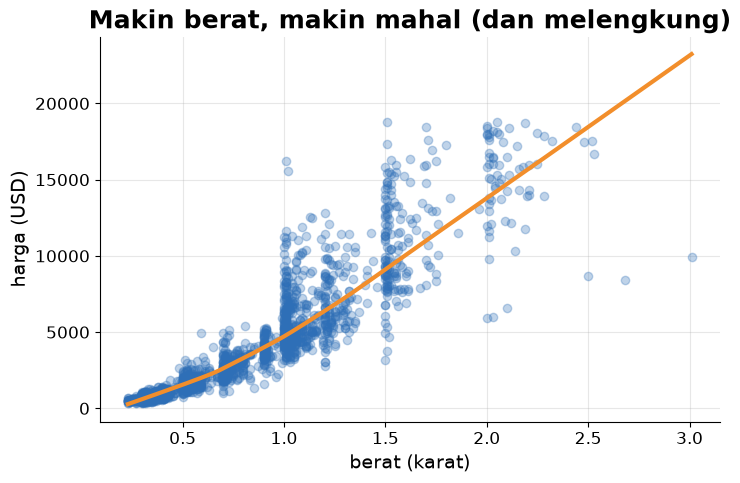

In [5]:
sample = diamonds.sample(2000, random_state=SEED)
sns.regplot(data=sample, x="carat", y="price", lowess=True,
            scatter_kws={"alpha": 0.3, "color": BLUE}, line_kws={"color": ORANGE, "linewidth": 3})
plt.title("Makin berat, makin mahal (dan melengkung)")
plt.xlabel("berat (karat)")
plt.ylabel("harga (USD)")
# Alternatif garis lurus: sns.regplot(data=sample, x="carat", y="price", order=1)
# Alternatif Matplotlib: plt.scatter(sample["carat"], sample["price"], alpha=0.3)
plt.savefig("hubungan_scatter_tren.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Scatter berwarna kategori
**Kapan dipakai:** ingin tahu apakah hubungan dua angka berbeda antar kelompok.
**Cara baca:** kalau warna terpisah rapi, kategori itu fitur penting (mis. asal mobil).

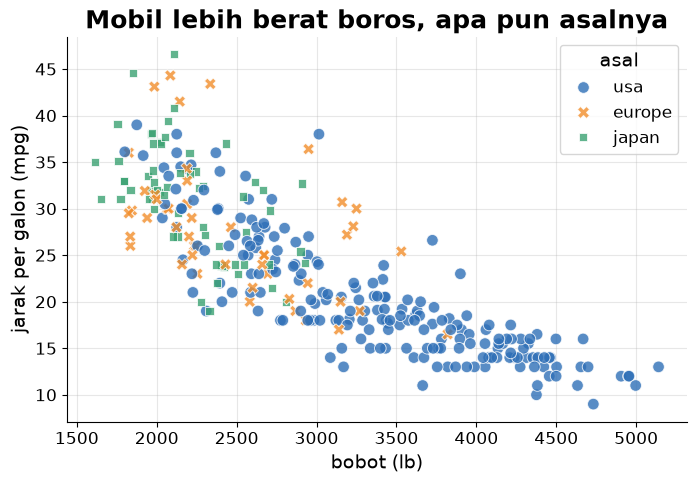

In [6]:
sns.scatterplot(data=cars, x="weight", y="mpg", hue="origin", style="origin", s=70, alpha=0.8)
plt.title("Mobil lebih berat boros, apa pun asalnya")
plt.xlabel("bobot (lb)")
plt.ylabel("jarak per galon (mpg)")
plt.legend(title="asal")
# Alternatif ukuran titik = kolom ketiga: sns.scatterplot(..., size="horsepower", sizes=(20, 200))
plt.savefig("hubungan_scatter_warna.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Hexbin (data besar)
**Kapan dipakai:** ribuan titik menumpuk sehingga scatter jadi blok warna tunggal.
**Cara baca:** tiap segi enam diwarnai jumlah titik (skala log), warna terang = padat.

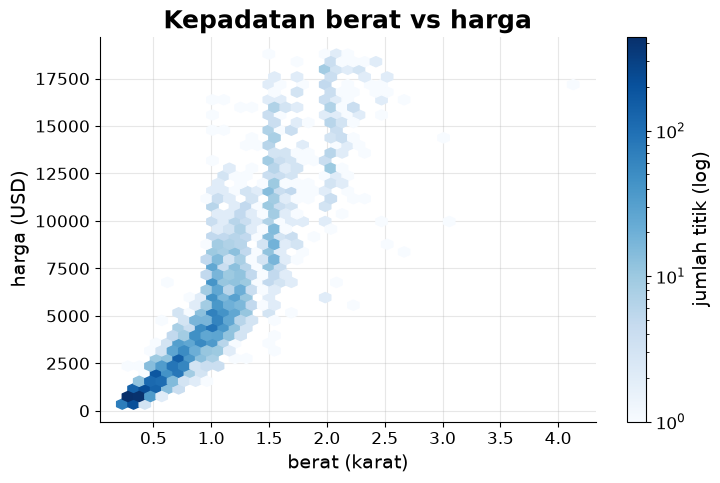

In [7]:
plt.hexbin(diamonds["carat"], diamonds["price"], gridsize=40, bins="log", mincnt=1, cmap="Blues")
plt.colorbar(label="jumlah titik (log)")
plt.title("Kepadatan berat vs harga")
plt.xlabel("berat (karat)")
plt.ylabel("harga (USD)")
# Alternatif seaborn: sns.histplot(data=diamonds, x="carat", y="price", bins=40, cbar=True)
# Alternatif kontur: sns.kdeplot(data=sample, x="carat", y="price", fill=True)
plt.savefig("hubungan_hexbin.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Heatmap korelasi bersegitiga
**Kapan dipakai:** ringkasan hubungan semua pasangan kolom angka, mencari fitur kembar.
**Cara baca:** merah = searah, biru = berlawanan, +-1 = sempurna. Segitiga atas dan
diagonal dibuang karena duplikat. Korelasi hanya menangkap hubungan lurus.

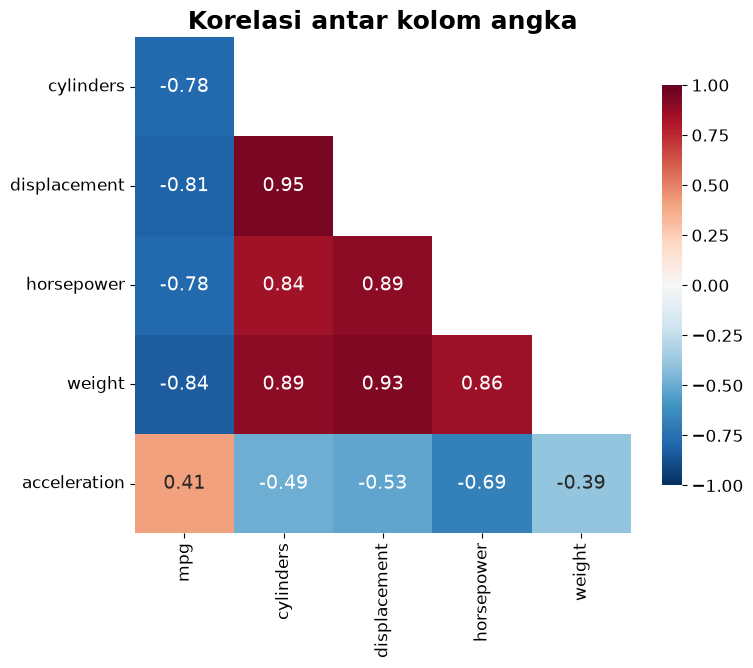

In [8]:
correlation = cars[NUMBER_COLS].corr()
lower = correlation.iloc[1:, :-1]
upper_mask = np.triu(np.ones_like(lower, dtype=bool), k=1)
plt.figure(figsize=(8, 6.5))
sns.heatmap(lower, mask=upper_mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Korelasi antar kolom angka")
plt.grid(False)
# Alternatif tahan outlier / hubungan melengkung: cars[NUMBER_COLS].corr(method="spearman")
plt.savefig("hubungan_korelasi.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Korelasi tiap kolom dengan target
**Kapan dipakai:** memilih fitur kandidat kuat, urutan kasar pentingnya fitur.
**Cara baca:** bar panjang = hubungan kuat, kanan = searah target, kiri = berlawanan.

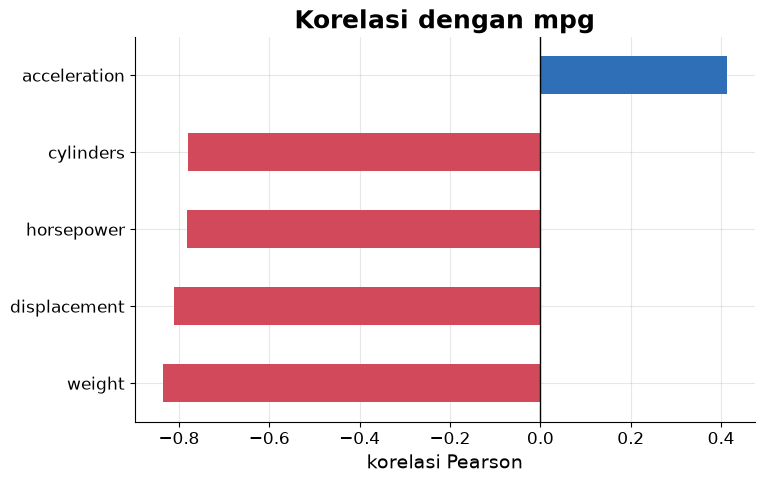

In [9]:
target_correlation = correlation[TARGET].drop(TARGET)
target_correlation = target_correlation.sort_values()
colors = []
for value in target_correlation:
    if value < 0:
        colors.append(RED)    # berlawanan arah
    else:
        colors.append(BLUE)   # searah
target_correlation.plot.barh(color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Korelasi dengan mpg")
plt.xlabel("korelasi Pearson")
plt.savefig("hubungan_korelasi_target.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Pairplot
**Kapan dipakai:** gambaran awal semua pasangan kolom sekaligus (untuk <= 6 kolom).
**Cara baca:** diagonal = sebaran tiap kolom, sel lain = scatter pasangan, warna = kelompok.

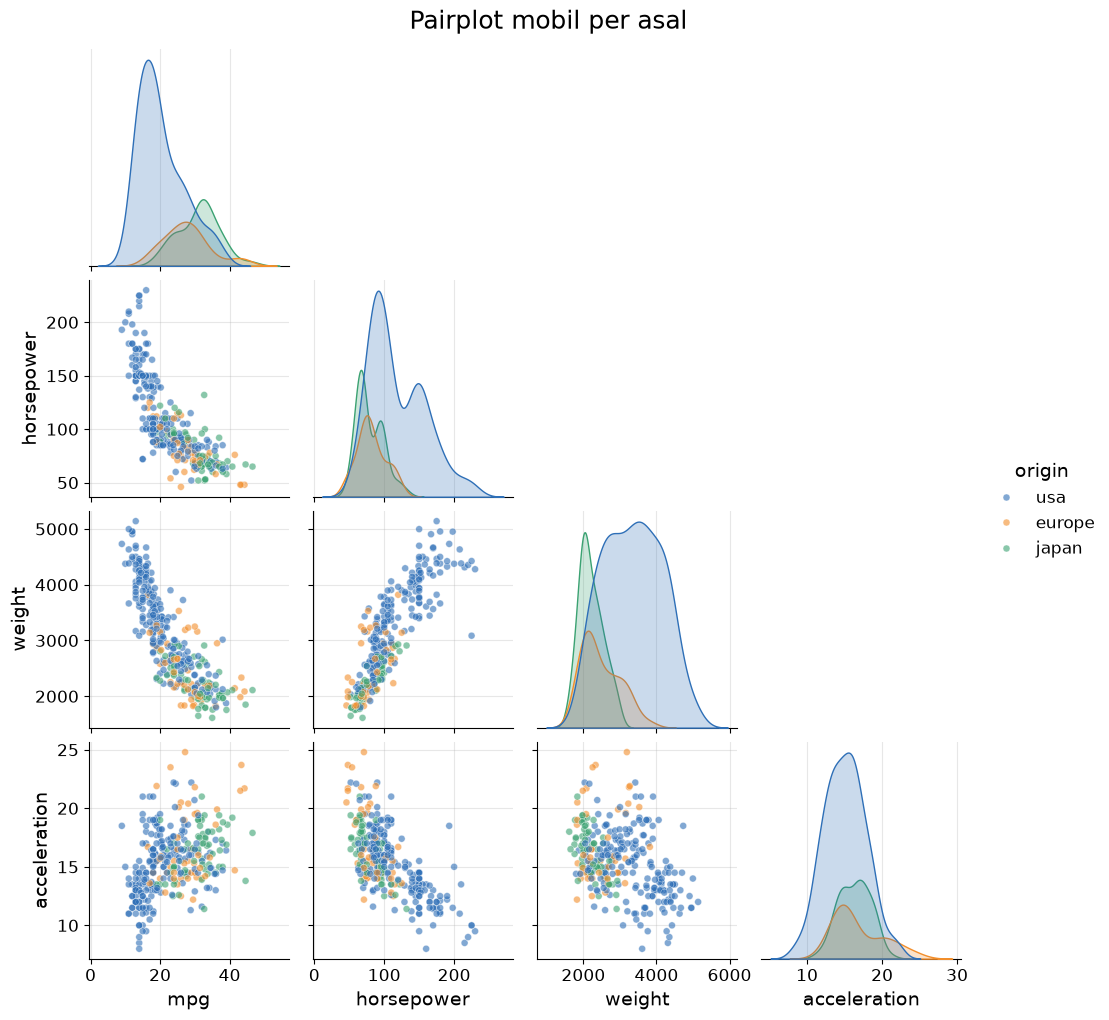

In [10]:
pair_cols = ["mpg", "horsepower", "weight", "acceleration", "origin"]
grid = sns.pairplot(cars[pair_cols], hue="origin", corner=True, plot_kws={"alpha": 0.6, "s": 25})
grid.figure.suptitle("Pairplot mobil per asal", y=1.02, fontsize=18)
# Alternatif lebih ringan untuk data besar: sns.pairplot(..., kind="hist")
grid.savefig("hubungan_pairplot.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Heatmap crosstab dua kategori
**Kapan dipakai:** dua kolom kategori, apakah kombinasi tertentu lebih sering dari biasanya?
**Cara baca:** angka = jumlah data. Kalau p-value uji chi-kuadrat kecil (< 0.05), keduanya
berhubungan.

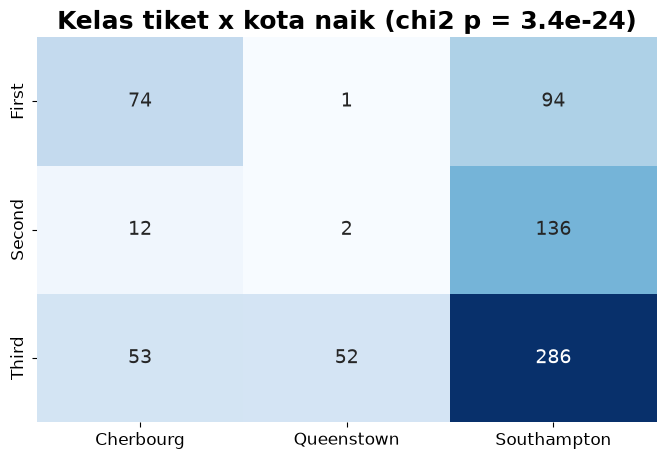

In [11]:
crosstab = pd.crosstab(titanic["class"], titanic["embark_town"])
p_value = chi2_contingency(crosstab)[1]
sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Kelas tiket x kota naik (chi2 p = {p_value:.1e})")
plt.xlabel("")
plt.ylabel("")
plt.grid(False)
# Alternatif persen per baris: pd.crosstab(..., normalize="index") * 100, fmt=".0f"
plt.savefig("hubungan_crosstab.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Scatter interaktif (plotly)
**Kapan dipakai:** ingin tahu titik mana yang menyimpang (hover nama/ID) atau memperbesar area.
**Cara baca:** arahkan kursor ke titik untuk melihat nama mobil dan angkanya.

In [12]:
fig = px.scatter(cars, x="weight", y="mpg", color="origin", hover_name="name",
                 hover_data=["horsepower", "model_year"], trendline="lowess",
                 color_discrete_sequence=PALETTE, title="Bobot vs mpg (interaktif)")
fig.write_html("hubungan_interaktif.html", include_plotlyjs=True)
fig.show()